# 가스 불량의 건조·과열·배기 가설: 전체와 run 내부 비교

공정 원인 후보를 기준으로 관측 신호를 확인한다. 원료 수분·수지 종류·건조기 노점·건조시간·금형 배기 상태·불량 사진이 없어 원인을 확정하지 않는다.

- 대회 범위 가스 30샷과 양쪽 모두 정상인 샷 비교. 미성형이 동시 발생한 CN7 2샷은 민감도 분석에서 제외한다.
- 전체, 후보 run별, 같은 라벨 관측 구간별, ±15분 정상 비교를 구분한다.
- 03/04와 같은 원본 연결·샷 통합·품질 필터·run 추정 기준을 사용한다.
- 새 온도 기울기는 같은 후보 run의 **이전 30분**만 사용한다. 적어도 10개의 유효 관측이 있을 때 계산한다.
- ±15분 정상 비교는 사후 EDA용이며 실시간 모델 피처가 아니다.
- 원인별 근거는 BASF/Covestro의 원인 분류에 맞추되, ‘온도 상승 = 수지 분해’ 또는 ‘호퍼 온도 = 건조 성능’이라고 해석하지 않는다.

BASF: https://plastics-rubber.basf.com/emea/en/performance_polymers/services/product_support_troubleshooting/injection_moulding_troubleshooter

Covestro: https://solutions.covestro.com/-/media/covestro/solution-center/brands/downloads/imported/1557310923.pdf?hash=CF29A8E0D4624E5941AC67E9C74AA279&rev=28b45997de9b4d4b841315b6018fd7b8

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, mannwhitneyu
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': ['Malgun Gothic', 'DejaVu Sans'], 'axes.unicode_minus': False, 'figure.dpi': 120})
raw = pd.read_csv(ROOT / 'data/original/moldset_labeled.csv')
raw['TimeStamp'] = pd.to_datetime(raw['TimeStamp'])
raw['product'] = raw['PART_NAME'].str.extract(r'^(CN7|RG3)', expand=False)
raw['cavity'] = raw['PART_NAME'].str.extract(r'(LH|RH)\s*$', expand=False)
raw['Reason'] = raw['Reason'].fillna('정상')
features = pd.read_csv(ROOT / 'data/moldset_labeled_cn7.csv', nrows=0).columns.drop(['Unnamed: 0', 'PassOrFail']).tolist()
raw['in_competition'] = False
mapping_checks = []
for product in ['CN7', 'RG3']:
    comp = pd.read_csv(ROOT / f'data/moldset_labeled_{product.lower()}.csv')
    candidate = raw.reset_index().set_index('Unnamed: 0')
    idx = comp['Unnamed: 0'].astype(int)
    aligned = candidate.loc[idx].reset_index(drop=True)
    assert aligned['product'].eq(product).all()
    assert np.array_equal(aligned['PassOrFail'].to_numpy(), comp['PassOrFail'].to_numpy())
    for f in features:
        x, y = aligned[f].to_numpy(float), comp[f].to_numpy(float)
        if np.ptp(x) < 1e-8:
            assert np.ptp(y) < 1e-8
            error = 0.
        else:
            coef = np.polyfit(x, y, 1)
            error = float(np.max(np.abs(np.polyval(coef, x)-y)))
            assert error < 1e-6, (product, f, error)
        mapping_checks.append({'product': product, 'feature': f, 'max_affine_error': error})
    raw.loc[aligned['index'].to_numpy(), 'in_competition'] = True
pd.DataFrame(mapping_checks).to_csv(TABLES / 'run_mapping_checks.csv', index=False)
print('Competition rows:', int(raw.in_competition.sum()), 'Original rows:', len(raw))
display(raw.groupby(['product', 'in_competition', 'Reason']).size().rename('rows').reset_index())

Competition rows: 2393 Original rows: 2607


,product,in_competition,Reason,rows
0,CN7,False,정상,204
1,CN7,False,초기허용불량,10
2,CN7,True,가스,13
3,CN7,True,미성형,4
4,CN7,True,정상,1194
5,RG3,True,가스,17
6,RG3,True,미성형,8
7,RG3,True,정상,1157


In [2]:
# 생산 이력: S14의 모든 제품을 남겨 제품 변경도 검출한다.
header = pd.read_csv(ROOT / 'data/original/unlabeled_data.csv', nrows=0).columns
usecols = ['TimeStamp', 'PART_NAME', 'EQUIP_CD'] + features
parts = []
for chunk in pd.read_csv(ROOT / 'data/original/unlabeled_data.csv', usecols=usecols, chunksize=50000):
    parts.append(chunk.loc[chunk['EQUIP_CD'].eq('S14')].copy())
history = pd.concat(parts, ignore_index=True)
history['TimeStamp'] = pd.to_datetime(history['TimeStamp'])
history['product'] = history['PART_NAME'].str.replace(r'[, ]+(LH|RH)\s*$', '', regex=True)
history.loc[history['PART_NAME'].str.startswith('CN7'), 'product'] = 'CN7'
history.loc[history['PART_NAME'].str.startswith('RG3'), 'product'] = 'RG3'
keys = ['EQUIP_CD', 'TimeStamp', 'product']
# Metadata only: never replace absent labels by normal.
labels = raw.groupby(keys, as_index=False).agg(
    PassOrFail=('PassOrFail', 'max'), in_competition=('in_competition', 'max'),
    original_rows=('PassOrFail', 'size'),
    bad_cavities=('cavity', lambda x: ''),
    Reason=('Reason', lambda x: '|'.join(sorted(set(x)-{'정상'})) or '정상'))
cavity_info = raw.loc[raw.PassOrFail.eq(1)].groupby(keys)['cavity'].agg(lambda x: '|'.join(sorted(set(x))))
labels = labels.drop(columns='bad_cavities').merge(cavity_info.rename('bad_cavities'), on=keys, how='left')
labels['bad_cavities'] = labels['bad_cavities'].fillna('')
records = pd.concat([raw[keys + features].assign(source='labeled'),
                     history[keys + features].assign(source='unlabeled')], ignore_index=True)
# Verify paired/repeated sensor values before selecting one record.
sensor_groups = records.groupby(keys)[features]
ranges = sensor_groups.max()-sensor_groups.min()
conflicts = ranges.gt(1e-4).any(axis=1)
conflict_table = ranges.loc[conflicts].reset_index()
conflict_table.to_csv(TABLES / 'run_duplicate_sensor_conflicts.csv', index=False)
print('Shots with conflicting paired/source measurements:', int(conflicts.sum()))
# Label source takes precedence if a source disagreement exists; conflicts are documented.
shots = records.drop_duplicates(keys, keep='first').merge(labels, on=keys, how='left')
shots['in_competition'] = shots['in_competition'].fillna(False).astype(bool)
shots = shots.sort_values(['EQUIP_CD', 'TimeStamp', 'product']).reset_index(drop=True)
ambiguous = shots.groupby(['EQUIP_CD', 'TimeStamp'])['product'].transform('size').gt(1)
assert not shots.loc[ambiguous, 'in_competition'].any(), 'Ambiguous competition shot'
shots.loc[ambiguous, keys].to_csv(TABLES / 'run_ambiguous_product_timestamps.csv', index=False)
print('Excluded ambiguous noncompetition timestamps:', shots.loc[ambiguous, 'TimeStamp'].nunique())
shots = shots.loc[~ambiguous].reset_index(drop=True)
shots = shots.merge(conflict_table[keys].assign(sensor_conflict=True), on=keys, how='left')
shots['sensor_conflict'] = shots['sensor_conflict'].fillna(False).astype(bool)
assert not shots.loc[shots.in_competition, 'sensor_conflict'].any(), 'Competition sensors conflict'
# Keep conflict timestamps for run boundaries, but exclude unreliable values from rolling history.
shots.loc[shots.sensor_conflict, features] = np.nan
shots['prev_gap_sec'] = shots.groupby('EQUIP_CD')['TimeStamp'].diff().dt.total_seconds()
print('Full observed history shots:', len(shots))
print('Competition shots:', shots.in_competition.sum(), 'bad shots:', shots.loc[shots.in_competition, 'PassOrFail'].sum())
display(labels.groupby(['product', 'in_competition']).agg(shots=('PassOrFail','size'), bad_shots=('PassOrFail','sum')))

Shots with conflicting paired/source measurements: 112
Excluded ambiguous noncompetition timestamps: 17
Full observed history shots: 68960
Competition shots: 1197 bad shots: 39.0


shots  bad_shots
product in_competition                  
CN7     False             107          5
        True              606         14
RG3     True              591         25

In [3]:
def assign_runs(frame, gap_minutes):
    out = frame.copy()
    switch = out['product'].ne(out.groupby('EQUIP_CD')['product'].shift())
    start = switch | out['prev_gap_sec'].gt(gap_minutes*60) | out['prev_gap_sec'].isna()
    out['run_number'] = start.cumsum()
    out['run_id'] = out.groupby('run_number')['TimeStamp'].transform('min').dt.strftime('%Y%m%d_%H%M%S') + '_' + out['product']
    out['observed_shot_seq'] = out.groupby('run_id').cumcount()+1
    out['run_elapsed_min'] = (out.TimeStamp-out.groupby('run_id').TimeStamp.transform('min')).dt.total_seconds()/60
    return out

sensitivity, run_tables = [], {}
for threshold in [5, 10, 30, 60]:
    framed = assign_runs(shots, threshold)
    contest = framed.loc[framed.in_competition]
    summary = contest.groupby(['product', 'run_id']).agg(
        labeled_shots=('PassOrFail','size'), bad_shots=('PassOrFail','sum'),
        labeled_start=('TimeStamp','min'), labeled_end=('TimeStamp','max'))
    summary['bad_rate'] = summary.bad_shots/summary.labeled_shots
    run_tables[threshold] = summary.reset_index()
    for p, g in summary.groupby(level=0):
        sensitivity.append({'gap_minutes': threshold, 'product': p, 'runs_with_labels': len(g),
                            'runs_with_defects': int(g.bad_shots.gt(0).sum()),
                            'largest_run_bad_share': g.bad_shots.max()/g.bad_shots.sum(),
                            'total_bad_shots': int(g.bad_shots.sum())})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(TABLES / 'run_threshold_sensitivity.csv', index=False)
shots = assign_runs(shots, 30)
contest = shots.loc[shots.in_competition].copy()
run_summary = run_tables[30]
full_runs = shots.groupby('run_id').agg(
    run_start=('TimeStamp','min'), run_end=('TimeStamp','max'), observed_shots=('TimeStamp','size'),
    max_internal_gap_sec=('prev_gap_sec', lambda x: x.iloc[1:].max()),
    source_labeled_only_shots=('source', lambda x: x.eq('labeled').sum()))
run_summary = run_summary.merge(full_runs, on='run_id', how='left')
run_summary.to_csv(TABLES / 'run_summary.csv', index=False, encoding='utf-8-sig')
display(run_summary)
display(sensitivity)
# Actual label coverage is uneven: denominators are labeled shots only, not all production.
contest[['run_id','TimeStamp','product','PassOrFail','Reason','bad_cavities','observed_shot_seq','run_elapsed_min','prev_gap_sec']].to_csv(
    TABLES / 'run_labeled_shots.csv', index=False, encoding='utf-8-sig')

,product,run_id,labeled_shots,bad_shots,labeled_start,labeled_end,bad_rate,run_start,run_end,observed_shots,max_internal_gap_sec,source_labeled_only_shots
0,CN7,20201016_035120_CN7,606,14.0,2020-10-16 04:57:47,2020-10-20 06:20:14,0.023102,2020-10-16 03:51:20,2020-10-20 06:20:14,8179,121.0,606
1,RG3,20201020_092218_RG3,341,15.0,2020-10-21 00:16:26,2020-10-22 08:09:24,0.043988,2020-10-20 09:22:18,2020-10-22 23:24:42,3575,126.0,341
2,RG3,20201023_010128_RG3,74,4.0,2020-10-23 01:01:28,2020-10-23 02:36:11,0.054054,2020-10-23 01:01:28,2020-10-23 02:36:11,74,1112.0,74
3,RG3,20201023_031215_RG3,176,6.0,2020-10-23 04:41:48,2020-10-23 07:46:03,0.034091,2020-10-23 03:12:15,2020-10-23 07:46:03,263,125.0,176


,gap_minutes,product,runs_with_labels,runs_with_defects,largest_run_bad_share,total_bad_shots
0,5,CN7,1,1,1.0,14
1,5,RG3,4,4,0.6,25
2,10,CN7,1,1,1.0,14
3,10,RG3,4,4,0.6,25
4,30,CN7,1,1,1.0,14
5,30,RG3,3,3,0.6,25
6,60,CN7,1,1,1.0,14
7,60,RG3,2,2,0.6,25


In [4]:
from scipy.stats import rankdata
# Original measured temperatures: 0 is treated as unavailable for thermal-profile summaries.
barrel_cols=[f'Barrel_Temperature_{i}' for i in range(1,7)]
barrel=shots[barrel_cols].where(shots[barrel_cols].gt(0))
complete=barrel.notna().all(axis=1)
shots=shots.copy()
shots['Barrel_Mean']=barrel.mean(axis=1).where(complete)
shots['Barrel_Max']=barrel.max(axis=1).where(complete)
shots['Barrel_Range']=(barrel.max(axis=1)-barrel.min(axis=1)).where(complete)
shots['Mold_Mean']=shots[['Mold_Temperature_3','Mold_Temperature_4']].where(
    shots[['Mold_Temperature_3','Mold_Temperature_4']].gt(0)).mean(axis=1)
shots['Mold_Delta']=shots.Mold_Temperature_4-shots.Mold_Temperature_3
# A degree/hour trend based exclusively on previous measurements in a true time window.
thermal=['Hopper_Temperature','Barrel_Mean','Mold_Mean']
computed=[]
for rid,g in shots.groupby('run_id',sort=False):
    g=g.copy().sort_values('TimeStamp')
    timestamp=pd.DatetimeIndex(g.TimeStamp)
    x=pd.Series((g.TimeStamp-g.TimeStamp.iloc[0]).dt.total_seconds().to_numpy()/3600,index=timestamp)
    for f in thermal:
        y=pd.Series(g[f].where(g[f].gt(0)).to_numpy(),index=timestamp)
        xx=x.where(y.notna())
        roll=lambda z: z.rolling('30min',closed='left',min_periods=10)
        mx,my=roll(xx).mean(),roll(y).mean()
        vx=roll(xx*xx).mean()-mx*mx
        cov=roll(xx*y).mean()-mx*my
        g[f+'__slope30min']=(cov/vx.where(vx.gt(1e-10))).to_numpy()
        g[f+'__past30min_mean']=my.to_numpy()
        g[f+'__dev30min']=g[f]-my.to_numpy()
    computed.append(g)
shots=pd.concat(computed,ignore_index=True).sort_values(['product','TimeStamp']).reset_index(drop=True)
contest=shots.loc[shots.in_competition].copy()
label_gap=contest.groupby('product').TimeStamp.diff().dt.total_seconds()
contest['label_block']=(contest['product'].ne(contest['product'].shift())|label_gap.isna()|label_gap.gt(1800)).cumsum()
contest['gas_flag']=contest.Reason.str.contains('가스',regex=False)
contest['mixed_shortshot']=contest.gas_flag&contest.Reason.str.contains('미성형',regex=False)
# Add already verified past-only features without recomputing them differently.
past=pd.read_csv(TABLES/'run_shot_feature_candidates.csv',parse_dates=['TimeStamp'])
past_cols=[f for f in past.columns if f.endswith(('__past10_std','__dev10'))]
contest=contest.merge(past[keys+past_cols],on=keys,how='left',validate='one_to_one')
gas=contest.loc[contest.gas_flag].copy()
assert len(gas)==30 and gas.mixed_shortshot.sum()==2
derived=['Barrel_Mean','Barrel_Max','Barrel_Range','Mold_Mean','Mold_Delta']
derived += [f+c for f in thermal for c in ['__slope30min','__past30min_mean','__dev30min']]
selected=['Hopper_Temperature','Plasticizing_Time','Max_Screw_RPM','Average_Screw_RPM',
          'Max_Back_Pressure','Average_Back_Pressure','Max_Injection_Speed','Max_Injection_Pressure',
          'Mold_Temperature_3','Mold_Temperature_4']+barrel_cols+derived+[
          'Barrel_Temperature_2__past10_std','Hopper_Temperature__past10_std',
          'Cushion_Position__past10_std','Max_Injection_Pressure__past10_std']
contest[keys+['run_id','label_block','PassOrFail','Reason','gas_flag','mixed_shortshot','run_elapsed_min']+selected].to_csv(
    TABLES/'gas_mechanism_shot_features.csv',index=False,encoding='utf-8-sig')
print('Derived temporal thermal profiles for',len(contest),'competition shots')


Derived temporal thermal profiles for 1197 competition shots


In [5]:
def auc_high(y,x):
    y=np.asarray(y,int);x=np.asarray(x,float)
    n1,n0=y.sum(),(1-y).sum()
    if not n1 or not n0:return np.nan
    return float((rankdata(x)[y==1].sum()-n1*(n1+1)/2)/(n1*n0))

# Whole product vs inferred-run vs label-observation block, with and without mixed defects.
rows=[]
for p,pg in contest.groupby('product'):
    for mode in ['all_gas','pure_gas']:
        target=pg.loc[pg.gas_flag&(~pg.mixed_shortshot if mode=='pure_gas' else True)]
        normal=pg.loc[pg.PassOrFail.eq(0)]
        for scope,groupcol in [('whole_product',None),('within_run','run_id'),('within_observation_block','label_block')]:
            groups=[('ALL',target)] if groupcol is None else list(target.groupby(groupcol))
            for group,tg in groups:
                ng=normal if groupcol is None else normal.loc[normal[groupcol].eq(group)]
                for f in selected:
                    t,n=tg[f].dropna(),ng[f].dropna()
                    if not len(t) or not len(n):continue
                    rows.append({'product':p,'mode':mode,'scope':scope,'group':str(group),'feature':f,
                                 'gas_n':len(t),'normal_n':len(n),'gas_mean':t.mean(),'normal_mean':n.mean(),
                                 'gas_median':t.median(),'normal_median':n.median(),
                                 'delta_mean':t.mean()-n.mean(),
                                 'auc_high':auc_high(np.r_[np.ones(len(t)),np.zeros(len(n))],np.r_[t,n])})
comparisons=pd.DataFrame(rows)
comparisons.to_csv(TABLES/'gas_mechanism_scope_comparisons.csv',index=False)
display(comparisons.loc[comparisons['mode'].eq('pure_gas')&comparisons.scope.eq('within_run')&
                         comparisons.feature.isin(['Hopper_Temperature','Barrel_Mean','Barrel_Max','Mold_Mean',
                          'Plasticizing_Time','Max_Screw_RPM','Barrel_Mean__slope30min','Mold_Mean__slope30min'])])
# Local same-run, same-product normal baselines. Minimum 3 normal observations.
local_rows=[]
for row in gas.itertuples():
    neighbors=contest.loc[contest['product'].eq(row.product)&contest.run_id.eq(row.run_id)&
                          contest.PassOrFail.eq(0)&(contest.TimeStamp-row.TimeStamp).dt.total_seconds().abs().le(15*60)]
    for f in selected:
        v=neighbors[f].dropna()
        local_rows.append({'product':row.product,'TimeStamp':row.TimeStamp,'run_id':row.run_id,
                          'mixed_shortshot':row.mixed_shortshot,'feature':f,'gas_value':getattr(row,f),
                          'normal_median':v.median(),'normal_n':len(v),
                          'difference':getattr(row,f)-v.median()})
local=pd.DataFrame(local_rows)
local.to_csv(TABLES/'gas_mechanism_local_differences.csv',index=False,encoding='utf-8-sig')
ls=[]
for (p,f),g in local.loc[~local.mixed_shortshot & local.normal_n.ge(3)].groupby(['product','feature']):
    v=g.dropna(subset=['difference'])
    d=v.difference.where(v.difference.abs().gt(1e-5),0)
    ls.append({'product':p,'feature':f,'gas_n':len(v),'median_difference':d.median(),'mean_difference':d.mean(),
               'positive':d.gt(0).sum(),'negative':d.lt(0).sum(),'ties':d.eq(0).sum()})
local_summary=pd.DataFrame(ls)
local_summary.to_csv(TABLES/'gas_mechanism_local_summary.csv',index=False)
display(local_summary.loc[local_summary.feature.isin(['Hopper_Temperature','Barrel_Mean','Barrel_Max',
                          'Plasticizing_Time','Max_Screw_RPM','Barrel_Mean__slope30min','Mold_Mean__slope30min'])])


,product,mode,scope,group,feature,gas_n,normal_n,gas_mean,normal_mean,gas_median,normal_median,delta_mean,auc_high
136,CN7,pure_gas,within_run,20201016_035120_CN7,Hopper_Temperature,11,592,67.445455,68.081587,67.300003,67.900002,-0.636132,0.309198
137,CN7,pure_gas,within_run,20201016_035120_CN7,Plasticizing_Time,11,592,16.926364,17.019409,16.920000,17.010000,-0.093045,0.174601
138,CN7,pure_gas,within_run,20201016_035120_CN7,Max_Screw_RPM,11,592,30.745455,30.794932,30.700001,30.799999,-0.049478,0.414466
152,CN7,pure_gas,within_run,20201016_035120_CN7,Barrel_Mean,11,592,263.671214,263.643356,263.683339,263.633334,0.027858,0.585227
153,CN7,pure_gas,within_run,20201016_035120_CN7,Barrel_Max,11,592,276.163641,276.189864,276.100006,276.200012,-0.026224,0.485028
155,CN7,pure_gas,within_run,20201016_035120_CN7,Mold_Mean,11,592,26.363637,24.090372,26.400001,24.050000,2.273265,0.900722
160,CN7,pure_gas,within_run,20201016_035120_CN7,Barrel_Mean__slope30min,11,592,-0.184239,0.000981,-0.123434,0.000522,-0.185220,0.270424
163,CN7,pure_gas,within_run,20201016_035120_CN7,Mold_Mean__slope30min,11,592,0.453398,0.302123,0.559074,0.256072,0.151275,0.626075
510,RG3,pure_gas,within_run,20201020_092218_RG3,Hopper_Temperature,10,326,66.130000,66.239571,66.099998,66.300003,-0.109571,0.429908
511,RG3,pure_gas,within_run,20201020_092218_RG3,Plasticizing_Time,10,326,12.936000,12.941564,12.935000,12.940000,-0.005565,0.465031


,product,feature,gas_n,median_difference,mean_difference,positive,negative,ties
2,CN7,Barrel_Max,11,-0.100006,0.049998,5,6,0
3,CN7,Barrel_Mean,11,0.033342,0.028032,7,4,0
6,CN7,Barrel_Mean__slope30min,11,-0.149214,-0.206883,0,11,0
16,CN7,Hopper_Temperature,11,0.300003,0.445455,9,1,1
25,CN7,Max_Screw_RPM,11,0.000000,0.022727,4,4,3
30,CN7,Mold_Mean__slope30min,11,0.162859,0.145071,7,4,0
33,CN7,Plasticizing_Time,11,0.010000,0.012273,8,2,1
36,RG3,Barrel_Max,17,0.000000,-0.011763,8,7,2
37,RG3,Barrel_Mean,17,0.050003,0.048529,9,7,1
40,RG3,Barrel_Mean__slope30min,16,-0.036359,-0.073341,5,11,0


In [6]:
# Do gas events occur more often in a rising rather than falling thermal state?
# Rates use labeled pure-gas or normal shots only; they are not the factory-wide defect rate.
eligible=contest.loc[contest.PassOrFail.eq(0)|(contest.gas_flag&~contest.mixed_shortshot)].copy()
state_rows=[]
for f,thresholds in [('Mold_Mean__slope30min',[0,.2,.5]),('Barrel_Mean__slope30min',[0,.1,.3]),
                      ('Hopper_Temperature__slope30min',[0,.2,.5])]:
    for threshold in thresholds:
        v=eligible.loc[eligible[f].notna()].copy()
        v['thermal_state']=np.select([v[f].gt(threshold),v[f].lt(-threshold)],['rising','falling'],default='flat')
        for (p,rid,state),g in v.groupby(['product','run_id','thermal_state']):
            state_rows.append({'feature':f,'threshold_per_hour':threshold,'product':p,'run_id':rid,'state':state,
                               'labeled_comparison_shots':len(g),'gas_shots':int(g.gas_flag.sum()),
                               'gas_fraction':g.gas_flag.mean()})
states=pd.DataFrame(state_rows)
states.to_csv(TABLES/'gas_thermal_state_run_rates.csv',index=False)
display(states.loc[states.feature.eq('Mold_Mean__slope30min')&states.threshold_per_hour.eq(.2)])
# Same observation block comparison also controls for label coverage.
obs_rows=[]
for f,threshold in [('Mold_Mean__slope30min',.2),('Barrel_Mean__slope30min',.1)]:
    v=eligible.loc[eligible[f].notna()].copy()
    v['thermal_state']=np.select([v[f].gt(threshold),v[f].lt(-threshold)],['rising','falling'],default='flat')
    for (p,bid,state),g in v.groupby(['product','label_block','thermal_state']):
        obs_rows.append({'feature':f,'product':p,'label_block':bid,'state':state,'shots':len(g),
                         'gas_shots':int(g.gas_flag.sum()),'gas_fraction':g.gas_flag.mean()})
pd.DataFrame(obs_rows).to_csv(TABLES/'gas_thermal_state_observation_rates.csv',index=False)
# Candidate run-level gas concentration and stable reference counts.
run_gas=contest.groupby(['product','run_id']).agg(
    labeled_shots=('TimeStamp','size'),normal_shots=('PassOrFail',lambda s:s.eq(0).sum()),
    gas_shots=('gas_flag','sum'),mixed=('mixed_shortshot','sum'),
    first_label=('TimeStamp','min'),last_label=('TimeStamp','max'))
run_gas['gas_per_labeled_shot']=run_gas.gas_shots/run_gas.labeled_shots
run_gas.to_csv(TABLES/'gas_mechanism_run_counts.csv',encoding='utf-8-sig')
display(run_gas)


,feature,threshold_per_hour,product,run_id,state,labeled_comparison_shots,gas_shots,gas_fraction
7,Mold_Mean__slope30min,0.2,CN7,20201016_035120_CN7,falling,85,1,0.011765
8,Mold_Mean__slope30min,0.2,CN7,20201016_035120_CN7,flat,162,2,0.012346
9,Mold_Mean__slope30min,0.2,CN7,20201016_035120_CN7,rising,356,8,0.022472
10,Mold_Mean__slope30min,0.2,RG3,20201020_092218_RG3,falling,24,1,0.041667
11,Mold_Mean__slope30min,0.2,RG3,20201020_092218_RG3,flat,158,3,0.018987
12,Mold_Mean__slope30min,0.2,RG3,20201020_092218_RG3,rising,154,6,0.038961
13,Mold_Mean__slope30min,0.2,RG3,20201023_010128_RG3,flat,2,0,0.000000
14,Mold_Mean__slope30min,0.2,RG3,20201023_010128_RG3,rising,61,2,0.032787
15,Mold_Mean__slope30min,0.2,RG3,20201023_031215_RG3,falling,13,0,0.000000
16,Mold_Mean__slope30min,0.2,RG3,20201023_031215_RG3,flat,66,1,0.015152


labeled_shots  normal_shots  gas_shots  mixed  \
product run_id                                                               
CN7     20201016_035120_CN7            606           592         13      2   
RG3     20201020_092218_RG3            341           326         10      0   
        20201023_010128_RG3             74            70          3      0   
        20201023_031215_RG3            176           170          4      0   

                                    first_label          last_label  \
product run_id                                                        
CN7     20201016_035120_CN7 2020-10-16 04:57:47 2020-10-20 06:20:14   
RG3     20201020_092218_RG3 2020-10-21 00:16:26 2020-10-22 08:09:24   
        20201023_010128_RG3 2020-10-23 01:01:28 2020-10-23 02:36:11   
        20201023_031215_RG3 2020-10-23 04:41:48 2020-10-23 07:46:03   

                             gas_per_labeled_shot  
product run_id                                     
CN7     20201016_035120_CN7              0.021452  
RG3     20201020_092218_RG3              0.029326  
        20201023_010128_RG3              0.040541  
        20201023_031215_RG3              0.022727

labeled_rows  gas_rows  normal_rows  gas_per_labeled_row
product cavity                                                          
CN7     LH               605         3          601             0.004959
        RH               606        10          593             0.016502
RG3     LH               591         0          591             0.000000
        RH               591        17          566             0.028765

Gas pairs: 30 Other side normal: 28 Maximum paired sensor mismatch: 0.0


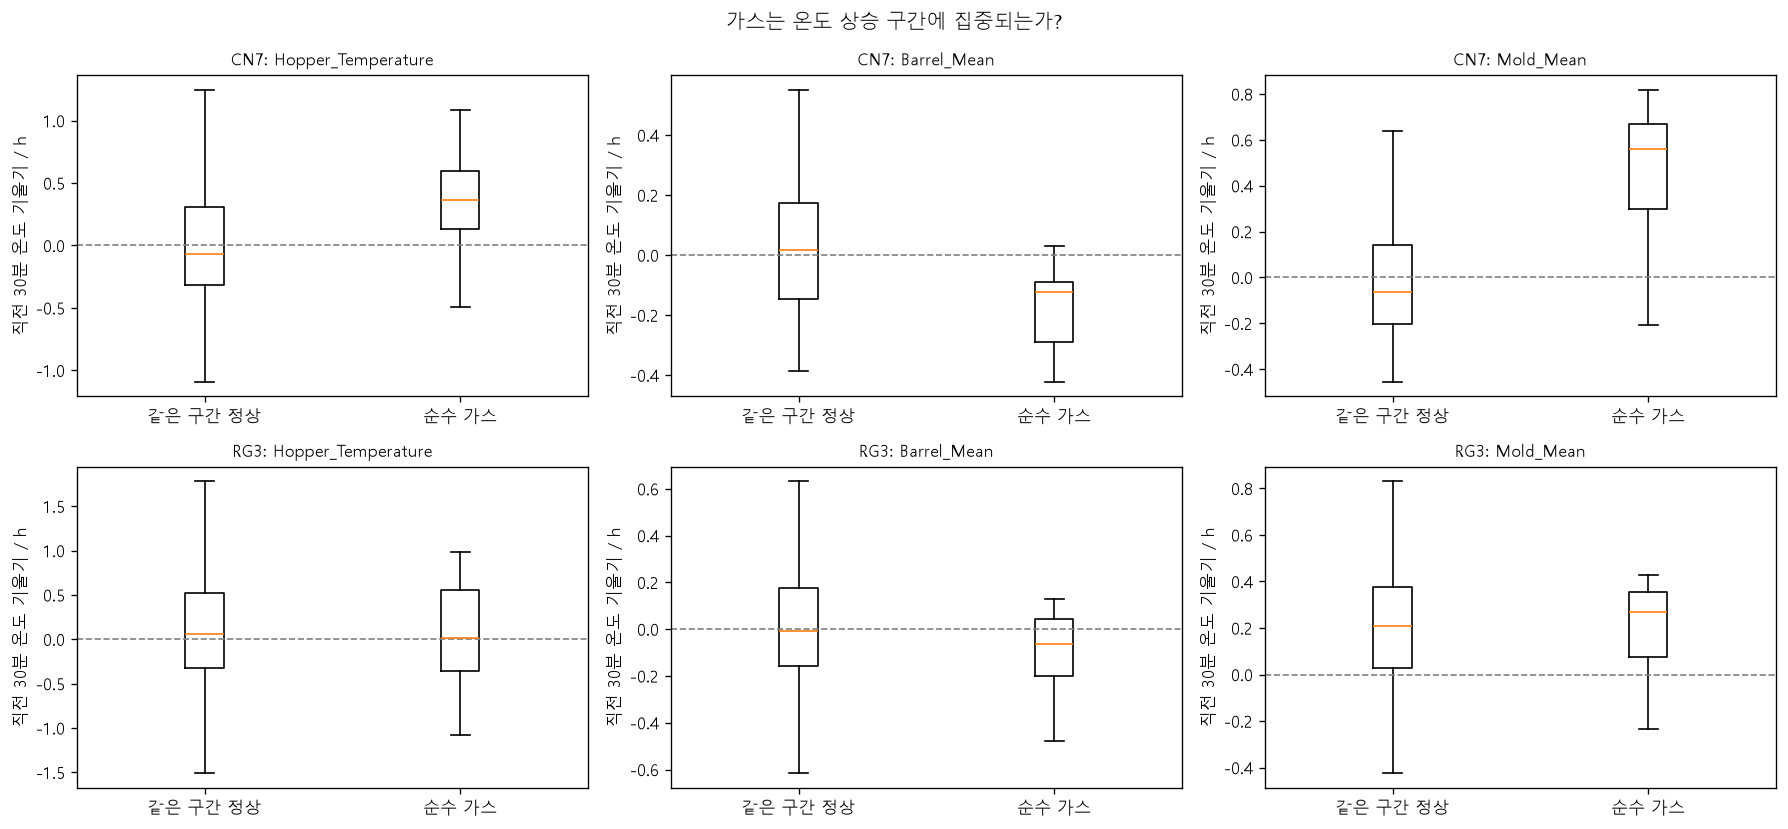

Verified prior-only temperature slope, all 30 gas shot pairs, unchanged shot count.


runs  gas_runs  gas_shots
gap_minutes product                           
5           CN7         1         1         13
            RG3         4         4         17
10          CN7         1         1         13
            RG3         4         4         17
30          CN7         1         1         13
            RG3         3         3         17
60          CN7         1         1         13
            RG3         2         2         17

,run_id,shots,gas_shots
0,20201020_092218_RG3,34,3
1,20201023_010128_RG3,5,0
2,20201023_031215_RG3,23,0


In [7]:
# Shared shot inputs and side-specific gas defects: pair the actual original cavity labels.
raw_comp=raw.loc[raw.in_competition].copy()
cavity_rates=raw_comp.groupby(['product','cavity']).agg(
    labeled_rows=('PassOrFail','size'),gas_rows=('Reason',lambda s:s.eq('가스').sum()),
    normal_rows=('PassOrFail',lambda s:s.eq(0).sum()))
cavity_rates['gas_per_labeled_row']=cavity_rates.gas_rows/cavity_rates.labeled_rows
cavity_rates.to_csv(TABLES/'gas_mechanism_cavity_rates.csv',encoding='utf-8-sig')
display(cavity_rates)
pairs=[]
for group,g in raw_comp.groupby(keys):
    if not g.Reason.eq('가스').any():continue
    other=g.loc[~g.Reason.eq('가스')]
    pairs.append(dict(zip(keys,group))|{'gas_cavity':'|'.join(g.loc[g.Reason.eq('가스'),'cavity']),
                 'other_cavity_label':'|'.join(other.Reason),'other_cavity_all_normal':bool(other.PassOrFail.eq(0).all()),
                 'sensor_max_difference':float((g[features].max()-g[features].min()).max())})
pair_info=pd.DataFrame(pairs)
pair_info.to_csv(TABLES/'gas_mechanism_paired_cavities.csv',index=False,encoding='utf-8-sig')
print('Gas pairs:',len(pair_info),'Other side normal:',pair_info.other_cavity_all_normal.sum(),
      'Maximum paired sensor mismatch:',pair_info.sensor_max_difference.max())
# Per-run context: compare gas with normal temperature slopes in the same labeled time range.
fig,axs=plt.subplots(2,3,figsize=(15,7))
for i,p in enumerate(['CN7','RG3']):
    for j,f in enumerate(['Hopper_Temperature__slope30min','Barrel_Mean__slope30min','Mold_Mean__slope30min']):
        ax=axs[i,j]
        g=contest.loc[contest['product'].eq(p)]
        valid_blocks=g.loc[g.gas_flag,'label_block'].unique()
        n=g.loc[g.PassOrFail.eq(0)&g.label_block.isin(valid_blocks),f].dropna()
        b=g.loc[g.gas_flag&~g.mixed_shortshot,f].dropna()
        ax.boxplot([n,b],tick_labels=['같은 구간 정상','순수 가스'],showfliers=False)
        ax.axhline(0,color='gray',linestyle='--',linewidth=1)
        ax.set_title(p+': '+f.replace('__slope30min',''),fontsize=10)
        ax.set_ylabel('직전 30분 온도 기울기 / h')
fig.suptitle('가스는 온도 상승 구간에 집중되는가?')
fig.tight_layout();fig.savefig(FIGURES/'gas_thermal_slopes_vs_normal.png',bbox_inches='tight');plt.show()
# Verify an actual prior-only slope manually at a gas case.
probe=gas.loc[gas['product'].eq('CN7')].iloc[0]
g=shots.loc[shots.run_id.eq(probe.run_id)&shots.TimeStamp.lt(probe.TimeStamp)&
            shots.TimeStamp.ge(probe.TimeStamp-pd.Timedelta(minutes=30))]
v=g[['TimeStamp','Mold_Mean']].dropna()
expected=np.polyfit((v.TimeStamp-v.TimeStamp.min()).dt.total_seconds()/3600,v.Mold_Mean,1)[0]
assert np.isclose(probe['Mold_Mean__slope30min'],expected,atol=1e-6)
assert len(pair_info)==30 and pair_info.other_cavity_all_normal.sum()==28
assert pair_info.sensor_max_difference.max()<1e-5
assert run_gas.gas_shots.sum()==30
assert len(contest)==1197
print('Verified prior-only temperature slope, all 30 gas shot pairs, unchanged shot count.')
# Different run-gap rules quantify dependence on the inferred boundary.
sensitivity_rows=[]
for minutes in [5,10,30,60]:
    framed=assign_runs(shots,minutes)
    labeled=framed.loc[framed.in_competition].copy()
    labeled['is_gas']=labeled.Reason.str.contains('가스',regex=False)
    for (p,rid),group in labeled.groupby(['product','run_id']):
        sensitivity_rows.append({'gap_minutes':minutes,'product':p,'run_id':rid,
                                 'labeled_shots':len(group),'gas_shots':int(group.is_gas.sum()),
                                 'first_label':group.TimeStamp.min(),'last_label':group.TimeStamp.max()})
sensitivity_gas=pd.DataFrame(sensitivity_rows)
sensitivity_gas.to_csv(TABLES/'gas_run_gap_sensitivity.csv',index=False,encoding='utf-8-sig')
display(sensitivity_gas.groupby(['gap_minutes','product']).agg(runs=('run_id','size'),gas_runs=('gas_shots',lambda x:x.gt(0).sum()),gas_shots=('gas_shots','sum')))
# One fixed recorded temperature can have both outcomes in distinct candidate runs.
example=contest.loc[contest['product'].eq('RG3')&contest['Barrel_Temperature_5'].round(1).eq(265.1)&
                    (contest.PassOrFail.eq(0)|contest.gas_flag)]
same_value=example.groupby('run_id').agg(shots=('TimeStamp','size'),gas_shots=('gas_flag','sum')).reset_index()
same_value.to_csv(TABLES/'gas_same_barrel_temperature_across_runs.csv',index=False)
display(same_value)
assert sensitivity_gas.loc[sensitivity_gas.gap_minutes.eq(30),'gas_shots'].sum()==30
